Exercise 14.X01: 

Perform data-driven function approximation of the two functions
f(x) = sin(x) and f(x) = exp(sin(x)) and find an accurate approximation using a
Neural Network architecture. When this is found, then compute the gradient function
using the neural network and compare the level of errors between the approximations.
Then, redo the data-driven function approximation while using this supervised
learning strategy to use information for both the function values and the gradients for
the corresponding input. Does the accuracy improve?

In [2]:
# import relevant packages
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

Data is sampled in the interval x∈[0,2π]

In [3]:
# Generate data
X = np.linspace(0,2*np.pi,30)
y_f1 = np.sin(X)
y_f2 = np.exp(np.sin(X))
Xtest = np.linspace(0,2*np.pi,2*30)
ytest_f1 = np.sin(Xtest)
ytest_f2 = np.exp(np.sin(Xtest))

Building a neural network arcithecture with 2 hidden layers and with 50 nodes in each layer using relu as the activation function

In [4]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 1)
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

Training a network that can aproximate the function f(x) = sin(x)

In [5]:
# Initializing network with MSE as the loss function and Adam as the optimizer 
# with 7000 epoch to train on
net_f1 = Net()
lr = 0.001 # learning rate, optimizer
criterion = nn.MSELoss()
n_epochs = 70000 # total epoch to train
optimizer = torch.optim.Adam(net_f1.parameters(), lr=lr)

In [6]:
# Reshaping data for NN structure
x_train = torch.as_tensor(X, dtype=torch.float32).reshape(-1, 1)
y_train = torch.as_tensor(y_f1, dtype=torch.float32).reshape(-1, 1)
x_test  = torch.as_tensor(Xtest, dtype=torch.float32).reshape(-1, 1)

In [7]:
losses = []
for epoch in range(1, n_epochs + 1):
    optimizer.zero_grad()
    loss = criterion(net_f1(x_train), y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 500 == 0:
        print(f'[{epoch}/{n_epochs}] loss: {loss.item():.6f}')

[500/70000] loss: 0.007536
[1000/70000] loss: 0.000174
[1500/70000] loss: 0.000114
[2000/70000] loss: 0.000094
[2500/70000] loss: 0.000093
[3000/70000] loss: 0.000096
[3500/70000] loss: 0.000091
[4000/70000] loss: 0.000165
[4500/70000] loss: 0.000091
[5000/70000] loss: 0.000091
[5500/70000] loss: 0.000092
[6000/70000] loss: 0.000091
[6500/70000] loss: 0.000915
[7000/70000] loss: 0.000091
[7500/70000] loss: 0.000091
[8000/70000] loss: 0.000091
[8500/70000] loss: 0.000119
[9000/70000] loss: 0.000091
[9500/70000] loss: 0.000091
[10000/70000] loss: 0.000091
[10500/70000] loss: 0.000091
[11000/70000] loss: 0.000122
[11500/70000] loss: 0.000127
[12000/70000] loss: 0.000091
[12500/70000] loss: 0.000091
[13000/70000] loss: 0.000091
[13500/70000] loss: 0.000084
[14000/70000] loss: 0.000082
[14500/70000] loss: 0.000077
[15000/70000] loss: 0.000091
[15500/70000] loss: 0.000076
[16000/70000] loss: 0.000086
[16500/70000] loss: 0.000068
[17000/70000] loss: 0.000100
[17500/70000] loss: 0.000089
[1800

Training a network that can aproximate the function f(x) = exp(sin(x))

In [8]:
# Initializing network with MSE as the loss function and Adam as the optimizer 
# with 7000 epoch to train on
net_f2 = Net()
lr = 0.001 # learning rate, optimizer
criterion = nn.MSELoss()
n_epochs = 70000 # total epoch to train
optimizer = torch.optim.Adam(net_f2.parameters(), lr=lr)

In [9]:
# Reshaping data for NN structure
x_train = torch.as_tensor(X, dtype=torch.float32).reshape(-1, 1)
y_train = torch.as_tensor(y_f2, dtype=torch.float32).reshape(-1, 1)
x_test  = torch.as_tensor(Xtest, dtype=torch.float32).reshape(-1, 1)

In [10]:
losses = []
for epoch in range(1, n_epochs + 1):
    optimizer.zero_grad()
    loss = criterion(net_f2(x_train), y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 500 == 0:
        print(f'[{epoch}/{n_epochs}] loss: {loss.item():.6f}')

[500/70000] loss: 0.033889
[1000/70000] loss: 0.012010
[1500/70000] loss: 0.005601
[2000/70000] loss: 0.003426
[2500/70000] loss: 0.002025
[3000/70000] loss: 0.001287
[3500/70000] loss: 0.001089
[4000/70000] loss: 0.001032
[4500/70000] loss: 0.001282
[5000/70000] loss: 0.000950
[5500/70000] loss: 0.000857
[6000/70000] loss: 0.000579
[6500/70000] loss: 0.000486
[7000/70000] loss: 0.000437
[7500/70000] loss: 0.000425
[8000/70000] loss: 0.000234
[8500/70000] loss: 0.000217
[9000/70000] loss: 0.000207
[9500/70000] loss: 0.000203
[10000/70000] loss: 0.001264
[10500/70000] loss: 0.000200
[11000/70000] loss: 0.000227
[11500/70000] loss: 0.000204
[12000/70000] loss: 0.000224
[12500/70000] loss: 0.000239
[13000/70000] loss: 0.000192
[13500/70000] loss: 0.000201
[14000/70000] loss: 0.000191
[14500/70000] loss: 0.000190
[15000/70000] loss: 0.000191
[15500/70000] loss: 0.000190
[16000/70000] loss: 0.000247
[16500/70000] loss: 0.000311
[17000/70000] loss: 0.000093
[17500/70000] loss: 0.000085
[1800

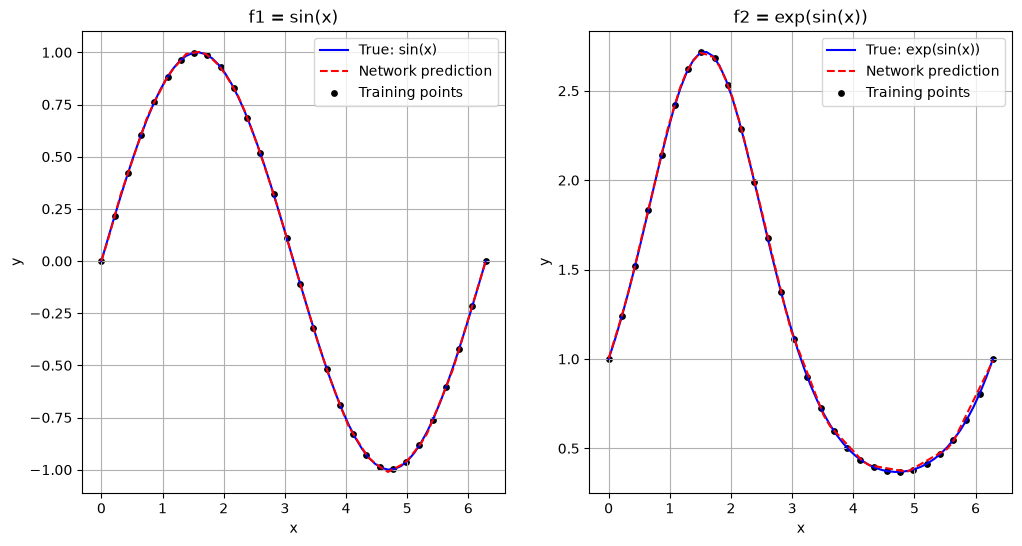

In [11]:
net_f1.eval()
with torch.no_grad():
    y_pred_f1 = net_f1(x_test).numpy().flatten()

net_f2.eval()
with torch.no_grad():
    y_pred_f2 = net_f2(x_test).numpy().flatten()

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].plot(Xtest, ytest_f1, 'b-', label='True: sin(x)')
ax[0].plot(Xtest, y_pred_f1, 'r--', label='Network prediction')
ax[0].scatter(X, np.sin(X), c='k', s=15, label='Training points')
ax[0].set_title("f1 = sin(x)")
ax[0].set_xlabel('x'); ax[0].set_ylabel('y')
ax[0].legend(); ax[0].grid(True)

ax[1].plot(Xtest, ytest_f2, 'b-', label='True: exp(sin(x))')
ax[1].plot(Xtest, y_pred_f2, 'r--', label='Network prediction')
ax[1].scatter(X, np.exp(np.sin(X)), c='k', s=15, label='Training points')
ax[1].set_title("f2 = exp(sin(x))")
ax[1].set_xlabel('x'); ax[1].set_ylabel('y')
ax[1].legend(); ax[1].grid(True)

Now to networks that accurately approximates the functions f1(x) = sin(x) and f2(x) = exp.sin(x) has been found 
and can be written as f1_NN(x) ≈ f1(x) = sin(x) and f2_NN(x) ≈ f2(x) = exp(sin(x)).

Now these approximations can be evaluated based on the function itself and the derivatives of the functions. 

The true derivatives of the functions are known as:
f1'(x) = cos(x)
f2'(x) = cos(x)*exp(sin(x))

these can then be compared to the gradient of the networks as

f1'(x) vs df1_NN(x)/dx

f2'(x) vs df2_NN(x)/dx

these are evaluated using the relative L2 norm

In [12]:
ytest_df1 = np.cos(Xtest)
ytest_df2 = np.cos(Xtest)*np.exp(np.sin(Xtest))

# test points with gradient tracking
x = torch.as_tensor(Xtest, dtype=torch.float32).reshape(-1, 1).requires_grad_(True)

f1_NN = net_f1(x)
f2_NN = net_f2(x)


df1_NN = torch.autograd.grad(
    outputs=f1_NN,
    inputs=x,
    grad_outputs=torch.ones_like(f1_NN),
)[0]
df2_NN = torch.autograd.grad(
    outputs=f2_NN,
    inputs=x,
    grad_outputs=torch.ones_like(f2_NN),
)[0]

# To numpy array
df1_NN = df1_NN.detach().numpy().flatten()
df2_NN = df2_NN.detach().numpy().flatten()


relL2_df1 = np.linalg.norm(ytest_df1 - df1_NN)/np.linalg.norm(ytest_df1)
relL2_df2 = np.linalg.norm(ytest_df2 - df2_NN)/np.linalg.norm(ytest_df2)

print(f"df1: relative L2 = {relL2_df1:.2e}")
print(f"df2: relative L2 = {relL2_df2:.2e}")


df1: relative L2 = 9.57e-02
df2: relative L2 = 1.41e-01


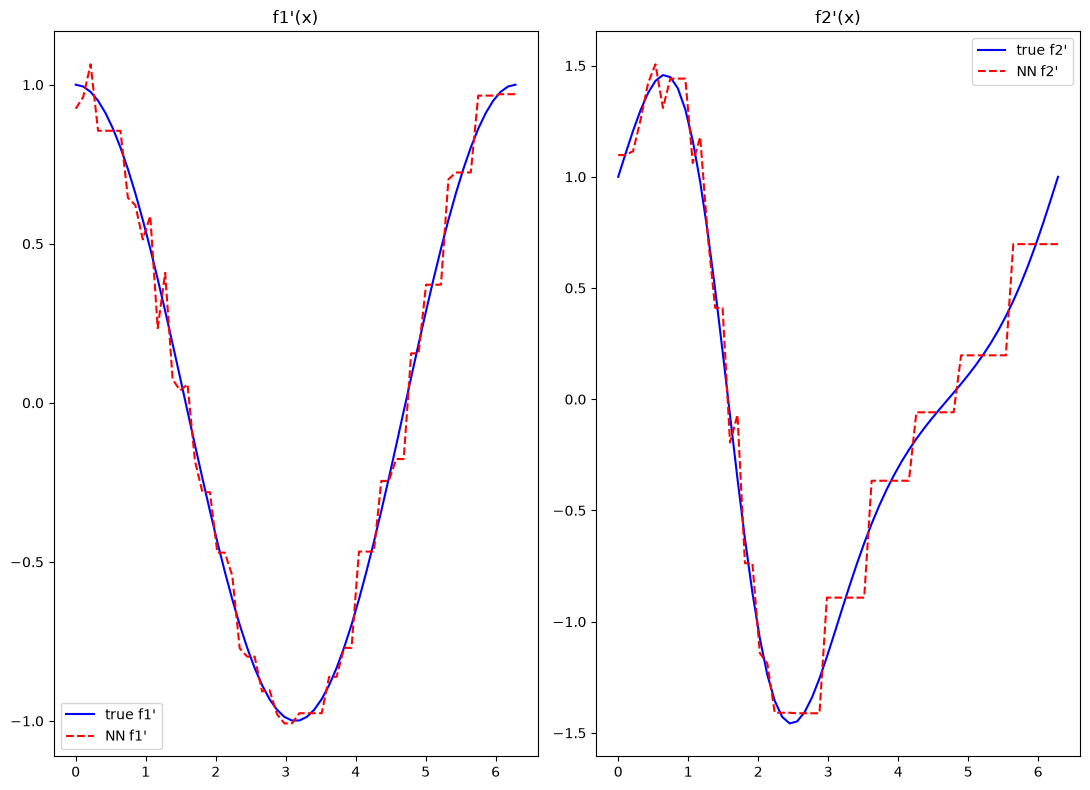

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 8))

# derivative vs. true derivative
ax[0].plot(Xtest, ytest_df1, 'b-', label="true f1'")
ax[0].plot(Xtest, df1_NN, 'r--', label="NN f1'")
ax[0].set_title("f1'(x)"); ax[0].legend()

ax[1].plot(Xtest, ytest_df2, 'b-', label="true f2'")
ax[1].plot(Xtest, df2_NN, 'r--', label="NN f2'")
ax[1].set_title("f2'(x)"); ax[1].legend()

plt.tight_layout()
plt.show()

It can be seen for both of these functions that the neural network approximates the function very well, however have a somewhat hard time approximating the derivatives of the functions.

Now its time to see wether an improvement can be made if the derivates are incorporated into the approximations

In [14]:
# Adding the derivatives to the dataset
y_df1 = np.cos(X)
y_df2 = np.cos(X)*np.exp(np.sin(X))
ytest_df1 = np.cos(Xtest)
ytest_df2 = np.cos(Xtest)*np.exp(np.sin(Xtest))

Building a neural network, that have two ouputs: function evaluation and the derivative evaluation. The network again have 2 hidden layers with 50 hidden notes in each layer and relu as the activation function.

In [15]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 1)
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

In [16]:
# Initializing network with MSE as the loss function and Adam as the optimizer 
# with 7000 epoch to train on
net_f1 = Net()
lr = 0.001 # learning rate, optimizer
criterion = nn.MSELoss()
n_epochs = 70000 # total epoch to train
optimizer = torch.optim.Adam(net_f1.parameters(), lr=lr)

In [1]:
# Reshaping data for NN structure with both the function evaluation and the derivative evaluation
x_train = torch.as_tensor(X, dtype=torch.float32).reshape(-1, 1).requires_grad_(True)
y_trainf1 = torch.as_tensor(y_f1, dtype=torch.float32).reshape(-1, 1)
y_traindf1 = torch.as_tensor(y_df1, dtype=torch.float32).reshape(-1, 1)
x_test  = torch.as_tensor(Xtest, dtype=torch.float32).reshape(-1, 1)

NameError: name 'torch' is not defined

In [ ]:
losses = []
for epoch in range(1, n_epochs + 1):
    optimizer.zero_grad()
    y = net_f1(x_train)
    dy = torch.autograd.grad(y, x_train, grad_outputs=torch.ones_like(y),
                             create_graph=True)[0]
    loss = criterion(y, y_trainf1) + criterion(dy, y_traindf1)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 500 == 0:
        print(f'[{epoch}/{n_epochs}] loss: {loss.item():.6f}')

[500/70000] loss: 0.009164
[1000/70000] loss: 0.008500
[1500/70000] loss: 0.008308
[2000/70000] loss: 0.008290
[2500/70000] loss: 0.008284
[3000/70000] loss: 0.008283
[3500/70000] loss: 0.007701
[4000/70000] loss: 0.007526
[4500/70000] loss: 0.007508
[5000/70000] loss: 0.007576
[5500/70000] loss: 0.007506
[6000/70000] loss: 0.007509
[6500/70000] loss: 0.007511
[7000/70000] loss: 0.007016
[7500/70000] loss: 0.007990
[8000/70000] loss: 0.007506
[8500/70000] loss: 0.007506
[9000/70000] loss: 0.007506
[9500/70000] loss: 0.007506
[10000/70000] loss: 0.007511
[10500/70000] loss: 0.007511
[11000/70000] loss: 0.007506
[11500/70000] loss: 0.007506
[12000/70000] loss: 0.007540
[12500/70000] loss: 0.004984
[13000/70000] loss: 0.004972
[13500/70000] loss: 0.004972
[14000/70000] loss: 0.004972
[14500/70000] loss: 0.005008
[15000/70000] loss: 0.004972
[15500/70000] loss: 0.004972
[16000/70000] loss: 0.004982
[16500/70000] loss: 0.005136
[17000/70000] loss: 0.004972
[17500/70000] loss: 0.004972
[1800

In [18]:
# Initializing network with MSE as the loss function and Adam as the optimizer 
# with 7000 epoch to train on
net_f2 = Net()
lr = 0.001 # learning rate, optimizer
criterion = nn.MSELoss()
n_epochs = 70000 # total epoch to train
optimizer = torch.optim.Adam(net_f2.parameters(), lr=lr)

In [19]:
# Reshaping data for NN structure with both the function evaluation and the derivative evaluation
x_train = torch.as_tensor(X, dtype=torch.float32).reshape(-1, 1).requires_grad_(True)
y_trainf2 = torch.as_tensor(y_f2, dtype=torch.float32).reshape(-1, 1)
y_traindf2 = torch.as_tensor(y_df2, dtype=torch.float32).reshape(-1, 1)
x_test  = torch.as_tensor(Xtest, dtype=torch.float32).reshape(-1, 1)

In [20]:
losses = []
for epoch in range(1, n_epochs + 1):
    optimizer.zero_grad()
    y = net_f2(x_train)
    dy = torch.autograd.grad(y, x_train, grad_outputs=torch.ones_like(y),
                             create_graph=True)[0]
    loss = criterion(y, y_trainf2) + criterion(dy, y_traindf2)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 500 == 0:
        print(f'[{epoch}/{n_epochs}] loss: {loss.item():.6f}')

[500/70000] loss: 0.137809
[1000/70000] loss: 0.045325
[1500/70000] loss: 0.045117
[2000/70000] loss: 0.038275
[2500/70000] loss: 0.011822
[3000/70000] loss: 0.011452
[3500/70000] loss: 0.009162
[4000/70000] loss: 0.008510
[4500/70000] loss: 0.008370
[5000/70000] loss: 0.008287
[5500/70000] loss: 0.008321
[6000/70000] loss: 0.008259
[6500/70000] loss: 0.008248
[7000/70000] loss: 0.008244
[7500/70000] loss: 0.008242
[8000/70000] loss: 0.008243
[8500/70000] loss: 0.008275
[9000/70000] loss: 0.008237
[9500/70000] loss: 0.008268
[10000/70000] loss: 0.008235
[10500/70000] loss: 0.008235
[11000/70000] loss: 0.008234
[11500/70000] loss: 0.008234
[12000/70000] loss: 0.008233
[12500/70000] loss: 0.008357
[13000/70000] loss: 0.008233
[13500/70000] loss: 0.008233
[14000/70000] loss: 0.008234
[14500/70000] loss: 0.008233
[15000/70000] loss: 0.008237
[15500/70000] loss: 0.008901
[16000/70000] loss: 0.008236
[16500/70000] loss: 0.008232
[17000/70000] loss: 0.008232
[17500/70000] loss: 0.008232
[1800

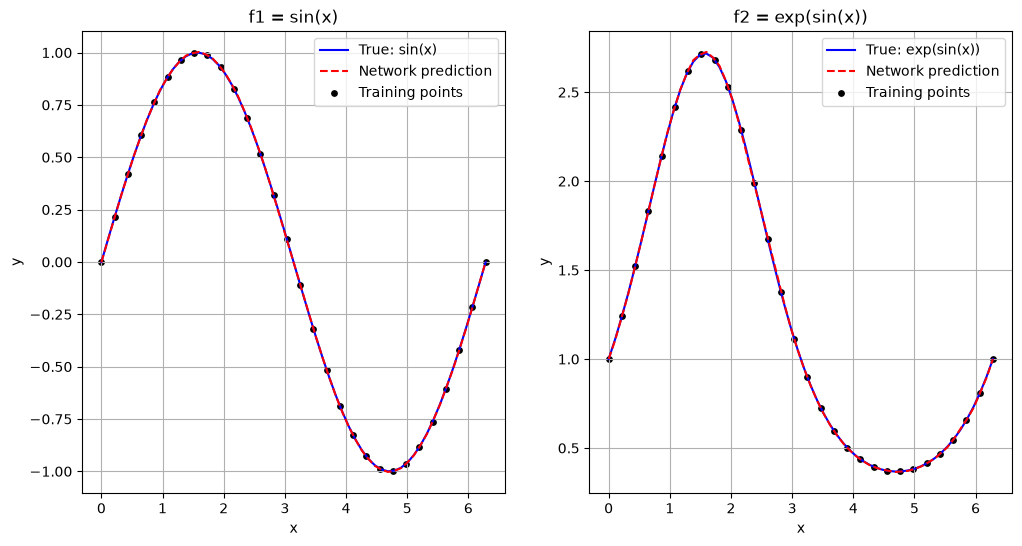

In [21]:
net_f1.eval()
with torch.no_grad():
    y_pred_f1 = net_f1(x_test).numpy().flatten()

net_f2.eval()
with torch.no_grad():
    y_pred_f2 = net_f2(x_test).numpy().flatten()

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].plot(Xtest, ytest_f1, 'b-', label='True: sin(x)')
ax[0].plot(Xtest, y_pred_f1, 'r--', label='Network prediction')
ax[0].scatter(X, np.sin(X), c='k', s=15, label='Training points')
ax[0].set_title("f1 = sin(x)")
ax[0].set_xlabel('x'); ax[0].set_ylabel('y')
ax[0].legend(); ax[0].grid(True)

ax[1].plot(Xtest, ytest_f2, 'b-', label='True: exp(sin(x))')
ax[1].plot(Xtest, y_pred_f2, 'r--', label='Network prediction')
ax[1].scatter(X, np.exp(np.sin(X)), c='k', s=15, label='Training points')
ax[1].set_title("f2 = exp(sin(x))")
ax[1].set_xlabel('x'); ax[1].set_ylabel('y')
ax[1].legend(); ax[1].grid(True)

In [22]:
# test points with gradient tracking
x = torch.as_tensor(Xtest, dtype=torch.float32).reshape(-1, 1).requires_grad_(True)

f1_NN = net_f1(x)
f2_NN = net_f2(x)


df1_NN = torch.autograd.grad(
    outputs=f1_NN,
    inputs=x,
    grad_outputs=torch.ones_like(f1_NN),
)[0]
df2_NN = torch.autograd.grad(
    outputs=f2_NN,
    inputs=x,
    grad_outputs=torch.ones_like(f2_NN),
)[0]

# To numpy array
df1_NN = df1_NN.detach().numpy().flatten()
df2_NN = df2_NN.detach().numpy().flatten()


relL2_df1 = np.linalg.norm(ytest_df1 - df1_NN)/np.linalg.norm(ytest_df1)
relL2_df2 = np.linalg.norm(ytest_df2 - df2_NN)/np.linalg.norm(ytest_df2)

print(f"df1: relative L2 = {relL2_df1:.2e}")
print(f"df2: relative L2 = {relL2_df2:.2e}")

df1: relative L2 = 5.85e-02
df2: relative L2 = 7.87e-02


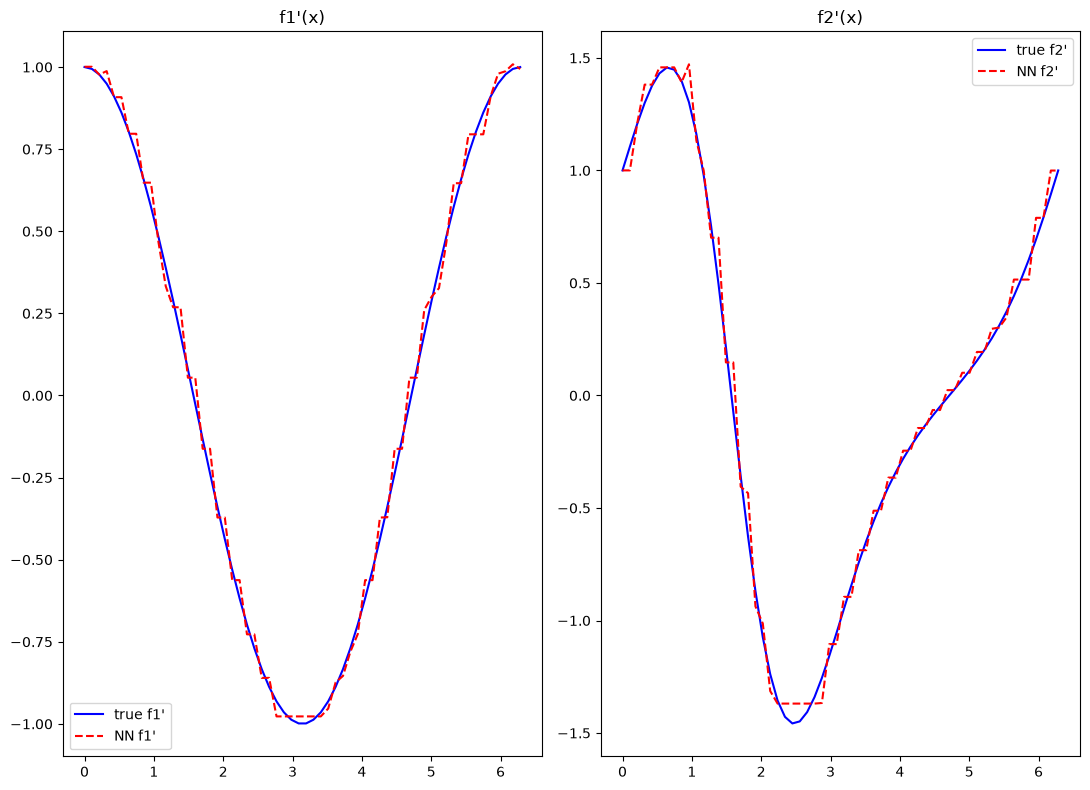

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 8))

# derivative vs. true derivative
ax[0].plot(Xtest, ytest_df1, 'b-', label="true f1'")
ax[0].plot(Xtest, df1_NN, 'r--', label="NN f1'")
ax[0].set_title("f1'(x)"); ax[0].legend()

ax[1].plot(Xtest, ytest_df2, 'b-', label="true f2'")
ax[1].plot(Xtest, df2_NN, 'r--', label="NN f2'")
ax[1].set_title("f2'(x)"); ax[1].legend()

plt.tight_layout()
plt.show()

Relative errors for the approximations without information about the gradients:

df1: relative L2 = 1.35e-01

df2: relative L2 = 9.91e-02

Relative errors for the approximations with information about the gradients:

df1: relative L2 = 5.85e-02

df2: relative L2 = 7.87e-02

From these it can be seen that the relative error does go down when using the gradients aswell for training the network. When adding the gradients the network is penalized for "wiggling" between datapoints, constraining the function, which gives a better fit.

The gradients are here seen as piecewise constant, this is due to the ReLU activation function which is constant. Another probably better activation function could have been the tanh as it can match smooth functions better. 